# Full Pipeline on the Quasar 3C 273

This notebook applies the pipeline of `full_star_tutorial.ipynb` to a quasar (up to the 18 of Nov). The shared data structures (`Spectrum`, `Line`, `Absorber`) are explained in section 1 of that tutorial and are not repeated here: we focus on what changes from an SDSS star to an HST/COS quasar.

We will study 3C 273, the brightest quasar in the sky, at $z = 0.158$. On its way to us its ultraviolet light crosses:

- the interstellar medium and the halo of the Milky Way: metal lines (Si II, S II, N I, C II, ...) at $v \approx 0$, and the damped Galactic $\mathrm{Ly}\alpha$ at 1216 Å;
- the Virgo cluster, in front of which 3C 273 lies: $\mathrm{Ly}\alpha$ at $cz \approx 1000-1600$ km/s;
- the low-redshift intergalactic medium: the $\mathrm{Ly}\alpha$ forest, from 1216 Å ($z = 0$) up to the $\mathrm{Ly}\alpha$ emission of the quasar itself, at $1216 \times 1.158 \approx 1408$ Å.

In [1]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt

## 1. Downloading and reading the quasar

3C 273 has no SDSS spectrum. Its ultraviolet spectrum comes from HST, which observed it in the far UV with two spectrographs: the Cosmic Origins Spectrograph (COS) and the Space Telescope Imaging Spectrograph (STIS). We use the co-adds of the Hubble Spectroscopic Legacy Archive (HSLA, STScI), which combine **all the exposures of a target taken with one grating** on a single wavelength grid:

- **COS G130M** (2012, 7 exposures, 4002 s): five central wavelengths (`cenwave`, set by tilting the grating), so the gap between the two detector segments and the detector artefacts fall at different wavelengths in each and are filled or diluted in the co-add. $R \approx 18\,000$.
- **STIS E140M** (2000, 7 exposures, 18 671 s): an echelle spectrum at $R \approx 46\,000$, with small gaps between echelle orders.

Besides the target, `query_mast` (`spectral_diag/mast_archive.py`) accepts any filter of astroquery's `Observations.query_criteria`; `provenance_name="HSLA"` keeps the co-adds. `download_mast_spectra` downloads the two far-UV ones by file name to `data/mast` (files already on disk are not downloaded again), and `read_hsla` (`spectral_diag/spectrum_reader.py`) turns each into a `Spectrum`, keeping only the pixels covered by at least one exposure. Wavelengths are vacuum, heliocentric. The files do not store the instrumental resolution: for COS the reader downloads the line spread function (LSF) measured by STScI for each exposure's setup and takes the median FWHM as `fwhm_kms`; for STIS it uses the nominal resolving power of the exposures.

In [2]:
from pathlib import Path

from spectral_diag.mast_archive import download_mast_spectra, query_mast
from spectral_diag.spectrum_reader import read_hsla

DOWNLOAD_DIR = Path("../data/mast")
# The far-UV co-adds; the archive also holds STIS G430L and G750L (optical)
COS_COADD_FILE = "hst_cos_3c273--0392_g130m-lp01_cspec.fits"
STIS_COADD_FILE = "hst_stis_3c273--0392_e140m_cspec.fits"

obs = query_mast("3C 273", provenance_name="HSLA")
download_mast_spectra(
    obs, download_dir=DOWNLOAD_DIR, productFilename=[COS_COADD_FILE, STIS_COADD_FILE]
)

cos_coadd = read_hsla(DOWNLOAD_DIR / COS_COADD_FILE)
stis_coadd = read_hsla(DOWNLOAD_DIR / STIS_COADD_FILE)
for coadd in (cos_coadd, stis_coadd):
    coadd.check_valid()
    print(
        f"{coadd.meta['instrument']:15s} {coadd.wave[0]:.1f}-{coadd.wave[-1]:.1f} A  "
        f"R {coadd.meta['R']:.0f}  exptime {coadd.meta['exptime']:.0f} s  "
        f"S/N {coadd.meta['snr']:.1f}"
    )

INFO: Found cached file ../data/mast/hst_cos_3c273--0392_g130m-lp01_cspec.fits with expected size 694080. [astroquery.query]


INFO: Found cached file ../data/mast/hst_stis_3c273--0392_e140m_cspec.fits with expected size 639360. [astroquery.query]
HST/COS G130M   1134.3-1470.3 A  R 18409  exptime 4002 s  S/N 38.6
HST/STIS E140M  1140.5-1709.5 A  R 45800  exptime 18671 s  S/N 20.1


The `meta` keys are those of the star tutorial (section 1.1 there), except the SDSS pipeline results (`z`, `class`, ...) and `pixel_dex`, which HST does not have. The reader adds:

| Key | Meaning |
|---|---|
| `cenwaves` | central wavelengths of the grating setups co-added, Å |

### 1.1 COS

We plot the flux and its error with `plot_raw_spectrum` (`spectral_diag/plots.py`). The broad bump around 1408 Å is the $\mathrm{Ly}\alpha$ emission of the quasar, and the black trough around 1216 Å is the damped Galactic $\mathrm{Ly}\alpha$, with the narrow geocoronal emission in its core (section 2.1).

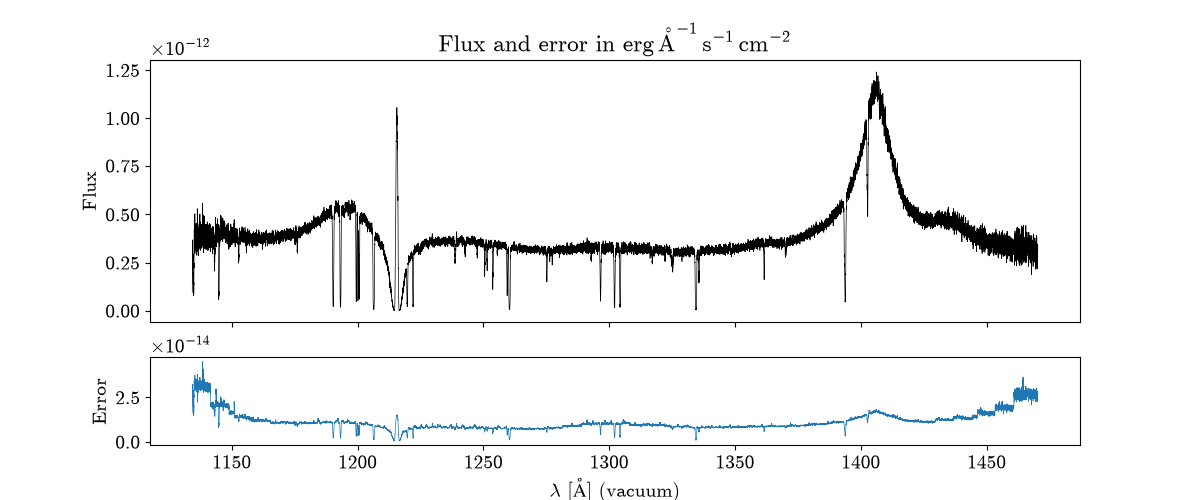

In [3]:
from spectral_diag.plots import plot_raw_spectrum

fig, axes = plot_raw_spectrum(cos_coadd)
plt.show()

### 1.2 STIS

STIS reaches further to the red, up to 1710 Å, with gaps between echelle orders at 1402.8–1404.8 Å and 1425.1–1428.2 Å (and a few below 1 Å above 1616 Å). Its error per pixel is higher despite 4.7× the exposure time: COS was designed for faint far-UV sources and collects many more photons per second.

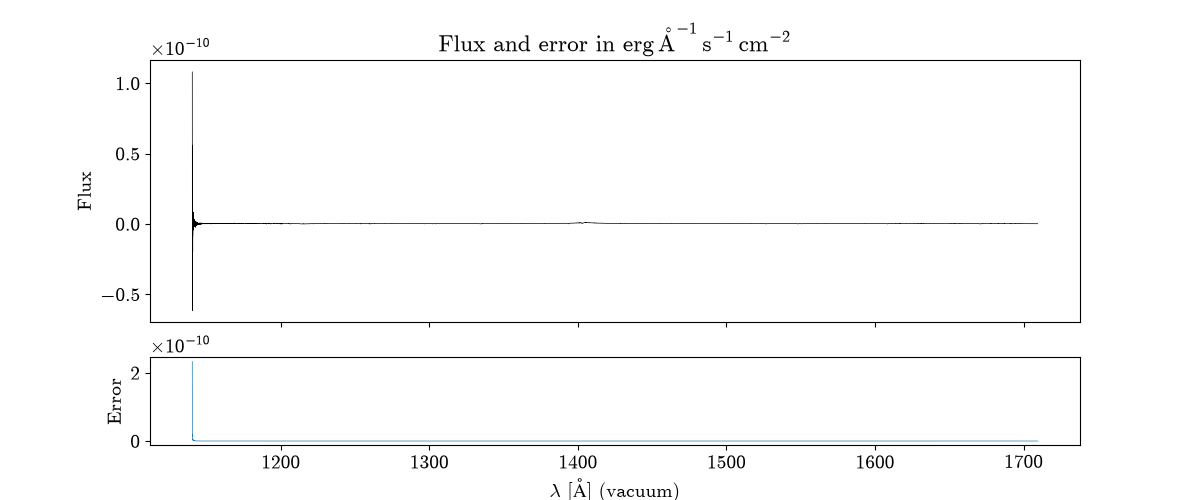

In [4]:
fig, axes = plot_raw_spectrum(stis_coadd)
plt.show()

### 1.3 COS against STIS

Both fluxes on the same axes. The STIS continuum is ~25% lower: 3C 273 is variable and the two spectra are 12 years apart. The narrower resolution element of STIS shows in deeper metal lines: zoom on the S II triplet (1250–1260 Å), where S II 1253.8 reaches 12% of the continuum in STIS against 32% in COS. COS, in turn, is much less noisy.

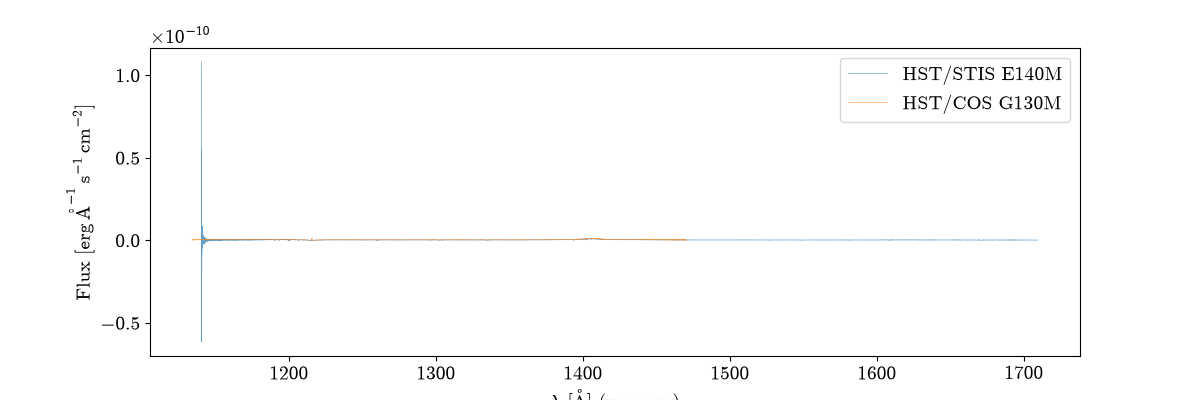

In [5]:
from spectral_diag.plots import WAVELENGTH_LABEL, latex_unit

fig, ax = plt.subplots(figsize=(12, 4))
for coadd in (stis_coadd, cos_coadd):
    ax.plot(
        coadd.wave, coadd.flux, linewidth=0.5, alpha=0.7, label=coadd.meta["instrument"]
    )
ax.set_xlabel(WAVELENGTH_LABEL)
ax.set_ylabel(f"Flux [{latex_unit(cos_coadd.meta['flux_unit'])}]")
ax.legend()
plt.show()

### 1.4 The pixel grid

From now on we use the COS co-add, for its S/N. Unlike SDSS, COS pixels are uniform in wavelength, about 0.01 Å each. In velocity they go from ~2.6 km/s at the blue end to ~2.0 km/s at the red end, while the instrumental FWHM is ~16 km/s ($R \approx 18\,000$, against ~2000 for SDSS). A resolution element therefore spans 6–8 pixels, compared with ~2 in SDSS: the line profiles are well sampled, but the noise of neighbouring pixels is correlated (section 3.1).

The velocity arguments of the star tutorial (section 2.2 there) still hold for the physics: widths, resolution and redshift act in km/s. Only the grid is different, so code that needs the pixel width in km/s must not assume a single value; `find_features` takes the median over the spectrum.

In [6]:
from spectral_diag import constants

spectrum = cos_coadd

pixel_width = np.median(np.diff(spectrum.wave))
print(f"pixel width: {pixel_width:.4f} A")

# Pixels uniform in Angstrom: in velocity, c * d(lambda) / lambda, they
# shrink to the red
for wave in (spectrum.wave[0], spectrum.wave[-1]):
    pixel_kms = constants.C_KMS * pixel_width / wave
    pixels_per_resolution_element = spectrum.meta["fwhm_kms"] / pixel_kms
    print(
        f"at {wave:.0f} A: {pixel_kms:.2f} km/s, "
        f"{pixels_per_resolution_element:.1f} pixels per resolution element"
    )

pixel width: 0.0100 A
at 1134 A: 2.65 km/s, 6.2 pixels per resolution element
at 1470 A: 2.04 km/s, 8.0 pixels per resolution element


## 2. Continuum

We use the same `fit_continuum` (`spectral_diag/continuum.py`) as for the star: a cubic spline with knots every `knot_spacing` Å, weighted by 1/error, refitted while rejecting the pixels more than `clip_low` errors below it (see section 3 of the star tutorial). Two things change for the quasar: an emission line that is not part of the quasar must be removed first, and the knots must be much closer.

### 2.1 Removing the geocoronal $\mathrm{Ly}\alpha$

The narrow emission at 1215.67 Å is **geocoronal $\mathrm{Ly}\alpha$**: solar $\mathrm{Ly}\alpha$ scattered by the hydrogen of the Earth's exosphere, around HST. It is not light from the quasar. It fills the whole 2.5″ aperture of COS, so its profile is flat-topped with a FWHM of ~0.85 Å, instead of the ~0.065 Å of a point source, and it sits in the black core of the Galactic $\mathrm{Ly}\alpha$, where the quasar flux is close to zero.

Left in, it breaks the continuum fit. In the first iterations it pulls the spline up; every pixel around it is then below the fit and rejected, the fit never comes back down, and the continuum overshoots to ~3× the flux. `fit_continuum` can also reject pixels above the fit (`clip_high`, infinite by default), but the cleanest fix is to cut the pixels: the core is black, so no absorption line can be measured there anyway.

In [7]:
# Covers the whole saturated core of the Galactic Ly-alpha, wider than the
# ~0.85 A flat top of the geocoronal emission (Angstrom)
GEOCORONAL_LYA_WINDOW = (1214.0, 1217.0)

in_geocoronal_lya = (spectrum.wave > GEOCORONAL_LYA_WINDOW[0]) & (
    spectrum.wave < GEOCORONAL_LYA_WINDOW[1]
)
spectrum = spectrum.cut(~in_geocoronal_lya)

### 2.2 Choosing the knot spacing

The default `knot_spacing` of 250 Å, chosen for the Balmer lines of the star, gives a single spline interval over the ~300 Å of COS, which cannot follow the shape of the quasar continuum (the broad $\mathrm{Ly}\alpha$ emission at 1408 Å, the Galactic $\mathrm{Ly}\alpha$ trough). The spacing must instead be narrower than the structures of the continuum and wider than the lines. We compared three values:

| `knot_spacing` | Galactic $\mathrm{Ly}\alpha$ trough (1208–1226 Å) | metal lines (e.g. S II and Si II, 1248–1262 Å) |
|---|---|---|
| 5 Å | bridged at ~4× the flux at its bottom | flat under the lines |
| 2 Å | followed down to the bottom | flat under the lines |
| 1 Å | followed | dips into the saturated Si II 1260 |

With 5 Å the spline cannot bend into the ~5 Å wide trough: the pixels at its bottom are rejected, the intervals there keep fewer than 10 used pixels, the knots are removed (`_knots`) and the spline bridges the trough. With 1 Å the knots are as narrow as the saturated lines and the spline starts following them. We keep 2 Å: the metal lines (≲ 1 Å) are narrower than that, the trough is wider.

**Caveat.** With 2 Å the damped Galactic $\mathrm{Ly}\alpha$ becomes part of the "continuum". That is what we want for detecting the metal lines on top of it, but its column density N(HI) cannot be measured against this continuum.

converged after 8 iterations
31399 of 33366 pixels used


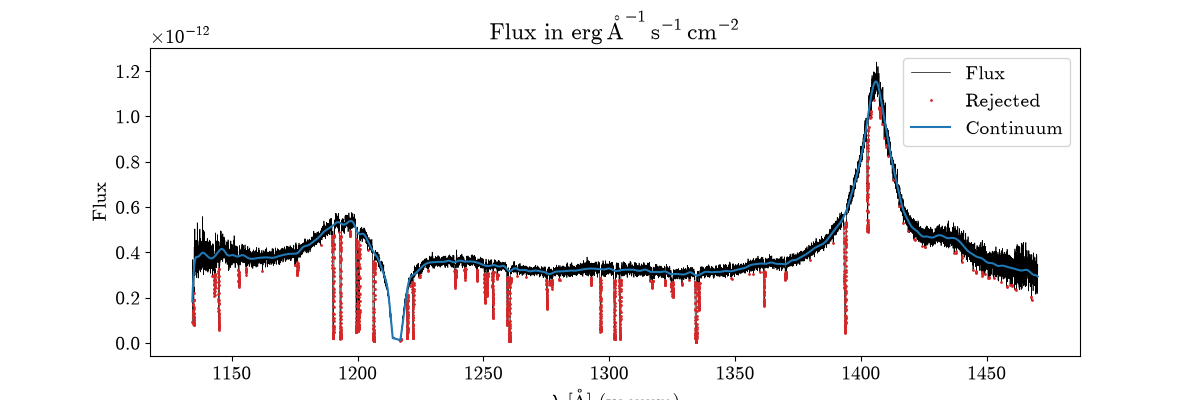

In [8]:
from spectral_diag.continuum import ContinuumSettings, fit_continuum
from spectral_diag.plots import plot_continuum

# Narrower than the Galactic Ly-alpha trough, wider than the metal lines
DETECTION_KNOT_SPACING = 2.0
# Margin over the default limit of 20 iterations
DETECTION_MAX_ITER = 50

detection_settings = ContinuumSettings(
    knot_spacing=DETECTION_KNOT_SPACING,
    max_iter=DETECTION_MAX_ITER,
    clip_low=4
)
fit = fit_continuum(spectrum, detection_settings)
print(f"{fit.status} after {fit.n_iter} iterations")
print(f"{fit.used.sum()} of {fit.used.size} pixels used")

fig, ax = plot_continuum(spectrum, fit)
plt.show()

### 2.3 Normalising

`normalise` divides the flux and the error by the continuum, as in section 3.3 of the star tutorial.

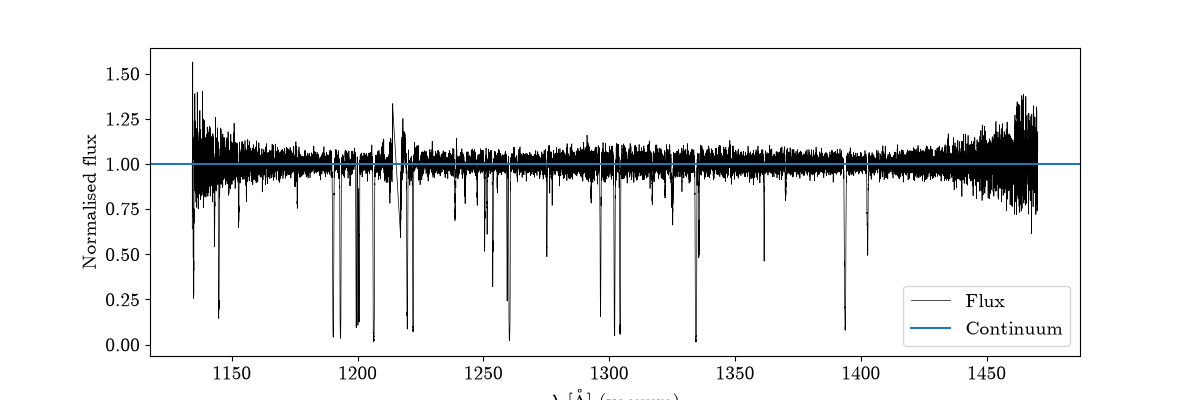

In [9]:
from spectral_diag.continuum import normalise
from spectral_diag.plots import plot_normalised

normalised_spectrum = normalise(spectrum, fit.continuum)

fig, ax = plot_normalised(normalised_spectrum)
plt.show()

The straight segment in the normalised spectrum is a gap of the pixel grid, not data: the cut geocoronal $\mathrm{Ly}\alpha$ (1214–1217 Å). Right after the cut, the normalised flux reaches ~3: there the continuum follows the bottom of the Galactic trough and is close to zero, so a pixel only $2\sigma$ above it gives a large ratio. Its error is just as large, so it does not affect the detection.

As for the star, `find_features` reads the continuum from `spectrum.continuum`, so we store the fit there, with its error in `spectrum.continuum_error`.

**Systematic error of the continuum.** `fit.error` is only the statistical error of the spline: with thousands of pixels at S/N ~40 it is tiny (~0.4% of the EW of the strong lines). The knot spacing of 2 Å is a choice, and the continuum depends on it. `continuum_systematic_error` refits with spacings 20% smaller and larger (1.6 and 2.4 Å) and takes the largest difference from the 2 Å fit at each pixel. Here it is ~1.4× the statistical error (median), and larger next to the strong lines. We add the two in quadrature.

In [10]:
from spectral_diag.continuum import continuum_systematic_error

systematic_error = continuum_systematic_error(spectrum, detection_settings)

spectrum.continuum = fit.continuum
# Propagated into the EW errors (ew_err) of the features
spectrum.continuum_error = np.hypot(fit.error, systematic_error)

## 3. Detecting the features

`find_features` (`spectral_diag/detect`) finds the significant dips without any line list, exactly as for the star (section 4 of the star tutorial, where the columns of the output table are described): it filters $1 - F_\mathrm{norm}$ with a Gaussian of the instrumental width and keeps the runs of pixels where the significance exceeds `threshold` (in $\sigma$).

### 3.1 The threshold

The $4\sigma$ of the star gives ~220 features here, most of them spurious.

**Correlated noise.** The matched filter assumes that the noise of each pixel is independent. In COS a resolution element spans 6–8 pixels, and the pipeline resamples and co-adds the exposures, so the noise of neighbouring pixels is correlated and the significance scatters by more than $1\sigma$. To measure where pure noise ends, we search for *emission* (`sign=+1`): this spectrum has no narrow emission lines, so every emission "feature" is noise. Below 1400 Å it stays under $9\sigma$ (apart from the wing of the geocoronal $\mathrm{Ly}\alpha$ just after the cut, at 1218.4 Å, which is real emission).

**The red end.** Above 1400 Å the noise reaches $\sim 12\sigma$ (1409.7 Å, on the $\mathrm{Ly}\alpha$ emission of the quasar). There fewer `cenwave` settings overlap (the co-added exposure time drops from 4002 s to ~1100 s at 1460 Å), so the detector artefacts of the red end of segment A (shadows of the grid wires, flat-field residuals) are less diluted.

We set the threshold at $12\sigma$, at the strongest noise feature. It keeps weak real lines such as N V 1242.7 (the partner of N V 1238.8), C I 1277.3 and Ni II 1370.1. Features above 1400 Å other than Si IV 1393.8 and 1402.8 must be treated with caution (e.g. 1407.4 Å).

In [11]:
from spectral_diag.detect import find_features

# At the strongest noise feature (emission, ~12 sigma at 1409.7 A); below
# 1400 A pure noise stays under 9 sigma
THRESHOLD = 12

features = find_features(spectrum, threshold=THRESHOLD)

print(f"{len(features)} features")
features.pprint_all()

44 features
  wave   wave_err wave_min wave_max depth   ew  ew_err   snr  
-------- -------- -------- -------- ----- ----- ------ -------
1134.846    0.004 1134.610 1135.069 0.745 0.206  0.010  20.550
1143.158    0.006 1142.827 1143.436 0.460 0.124  0.005  24.028
1144.876    0.003 1144.583 1145.430 0.856 0.316  0.007  43.521
1152.767    0.005 1152.281 1152.979 0.352 0.098  0.008  13.046
1155.820    0.007 1155.532 1156.210 0.209 0.037  0.004   9.237
1176.066    0.004 1175.815 1176.374 0.246 0.066  0.004  16.698
1190.337    0.003 1189.746 1190.883 0.959 0.503  0.008  59.695
1193.230    0.003 1192.449 1193.715 0.966 0.487  0.016  30.497
1197.089    0.008 1196.647 1197.644 0.122 0.031  0.014   2.190
1199.500    0.003 1199.160 1199.828 0.907 0.324  0.008  41.959
1200.181    0.003 1199.878 1200.417 0.894 0.297  0.009  34.985
1200.662    0.003 1200.426 1201.095 0.875 0.274  0.012  22.808
1206.431    0.006 1205.951 1207.058 0.983 0.615  0.005 119.716
1219.756    0.001 1219.354 1220.221 0.915 0

### 3.2 The windows

`plot_features` (`spectral_diag/plots.py`) draws the normalised spectrum with the window of each feature shaded and its centre marked. With `%matplotlib widget` the plot can be zoomed with the toolbar.

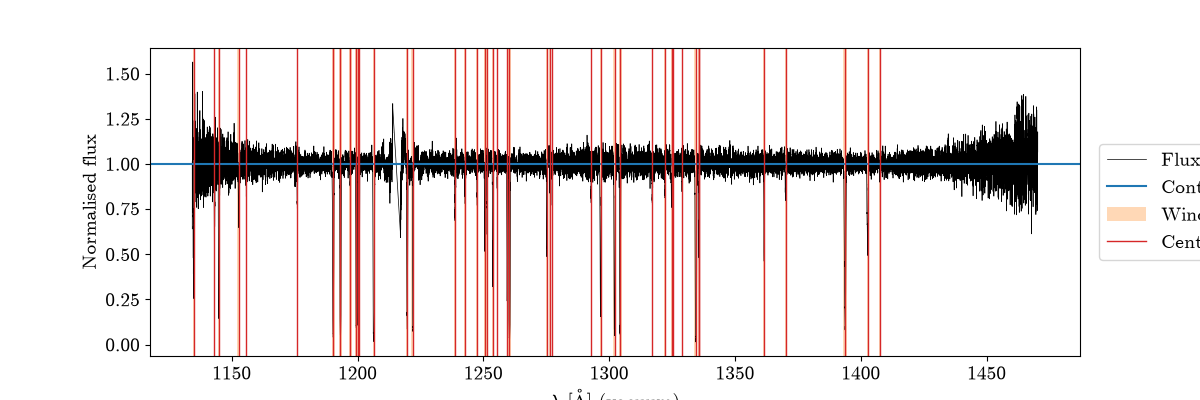

In [12]:
from spectral_diag.plots import plot_features

fig, ax = plot_features(normalised_spectrum, features)
plt.show()

## 4. Identifying the features

`identify` (`spectral_diag/detect`) slides the "comb" of each species over the features: the lines of a species keep their wavelength ratios at any velocity, so each feature is tried as each line of each species, and a velocity where at least 3 lines of one species land on features (within 15 km/s, with plausible strength ratios) defines an absorption system. Every species is then labelled at that velocity, within 10 km/s, including those with a single line in the spectrum. The search repeats on the features left. It is validated on synthetic COS spectra in `07_identification.ipynb`.

We try every species with a line table in `data/line_lists/`; those with no line in the COS range are skipped.

In [13]:
from spectral_diag.detect import identify

SPECIES = [
    "HI", "HeI", "HeII", "CI", "CII", "CIV", "NI", "NV", "OI", "OVI",
    "NaI", "MgII", "AlII", "SiII", "SiIII", "SiIV", "SII", "CaII", "FeII",
]

identified = identify(features, spectrum, SPECIES)

for velocity in identified.meta["systems"]:
    print(f"system at v = {velocity:.1f} km/s")
identified["wave", "ew", "ew_err", "species", "line", "v"].pprint_all()

system at v = -12.7 km/s
  wave     ew  ew_err species      line               v         
-------- ----- ------ ------- -------------- -------------------
1134.846 0.206  0.010                                        nan
1143.158 0.124  0.005    FeII  FeII 1143.226 -17.636326075040614
1144.876 0.316  0.007    FeII  FeII 1144.939 -16.501323316752586
1152.767 0.098  0.008                                        nan
1155.820 0.037  0.004                                        nan
1176.066 0.066  0.004                                        nan
1190.337 0.503  0.008    SiII  SiII 1190.416 -19.846513622715424
1193.230 0.487  0.016    SiII  SiII 1193.290 -15.109015122075743
1197.089 0.031  0.014                                        nan
1199.500 0.324  0.008      NI    NI 1199.550 -12.377224238002562
1200.181 0.297  0.009      NI    NI 1200.223 -10.683432161367957
1200.662 0.274  0.012      NI    NI 1200.710 -12.042807319384618
1206.431 0.615  0.005   SiIII SiIII 1206.499 -16.961894406171282


`identify` finds a single system, the **Milky Way at $v \approx -13$ km/s**, and labels 19 of the 44 features: Fe II, Si II, N I, Si III, N V, S II, C I, O I, C II and Si IV. The lines needed for the curve of growth are all there: the S II triplet (1250, 1253, 1259 Å), within 1 km/s of each other, and the four Si II lines (1190, 1193, 1260, 1304 Å).

Si II 1190 needs the systematic error of the continuum (section 2.3). Both 1190 and 1193 are saturated, so their EWs are almost equal, and the measured 1190 one is even 3% larger, although its $f\lambda$ is half that of 1193. With the statistical error alone (~0.5%) the strength check of `identify` rejects it.

Not labelled:

- **Si IV 1393.8**: at $+4$ km/s, 17 km/s from the system, beyond the 10 km/s labelling tolerance. Its EW is also 2.6× that of Si IV 1402.8, more than the 2× of their $f\lambda$: probably a blend.
- **Virgo $\mathrm{Ly}\alpha$** (1219.8 and 1222.1 Å, $cz \approx 1000$ and $1600$ km/s): HI has only one line in the COS range, so it cannot form a comb of 3 lines, and these velocities are outside the ±600 km/s searched.
- species without a line table (P II 1152.8, Ni II 1317.2 and 1370.1), excited levels (C II* 1335.7) and the $\mathrm{Ly}\alpha$ forest.

## 5. Curve of growth

For a species with several lines from the same lower level, the equivalent widths depend on only two parameters of the gas: its column density $N$ and its Doppler parameter $b$. `fit_cog` (`spectral_diag/curve_of_growth.py`) finds the $(\log N, b)$ whose theoretical equivalent widths best match the measured ones ($\chi^2$ fit), for a single cloud at the system velocity found by `identify`.

We fit the two species with enough lines: S II (1250, 1253, 1259 Å) and Si II (1190, 1193, 1260, 1304 Å). The EWs and their errors (noise, statistical and systematic continuum errors) are those measured by `find_features` over each feature's window.

In [14]:
from spectral_diag.curve_of_growth import fit_cog, measured_ews
from spectral_diag.line_list import get_lines

COG_SPECIES = ["SII", "SiII"]

system_redshift = identified.meta["systems"][0] / constants.C_KMS

cog_fits = {}
for species in COG_SPECIES:
    ews = measured_ews(identified, species)
    cog_fit = fit_cog(get_lines(species), ews, z=system_redshift)
    cog_fits[species] = cog_fit
    print(
        f"{species:5s} log N = {cog_fit['logN']:.2f} +- {cog_fit['logN_err']:.2f}  "
        f"b = {cog_fit['b']:.1f} +- {cog_fit['b_err']:.1f} km/s  "
        f"chi2 = {cog_fit['chi2']:.1f} for {cog_fit['dof']} dof"
    )

SII   log N = 15.33 +- 0.04  b = 21.8 +- 2.1 km/s  chi2 = 5.0 for 1 dof


SiII  log N = 15.08 +- 0.06  b = 31.4 +- 1.0 km/s  chi2 = 31.4 for 2 dof


`plot_curve_of_growth` (`spectral_diag/plots.py`) puts each line at $\log_{10}(N f \lambda)$ for the fitted $N$, so all the lines of a species fall on the curve of the fitted $b$ when the fit is good.

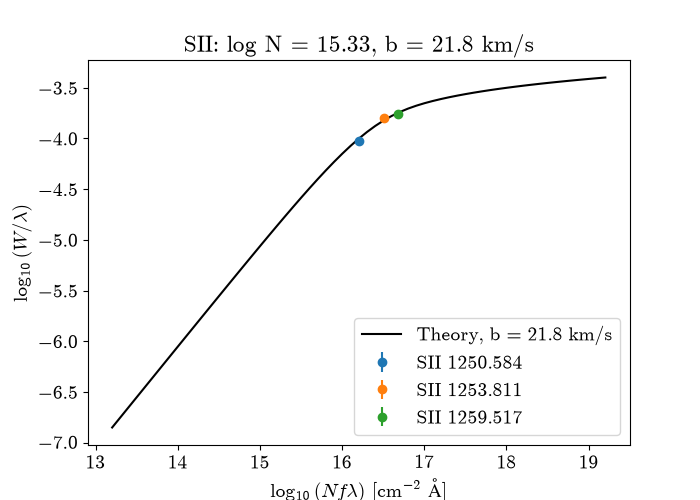

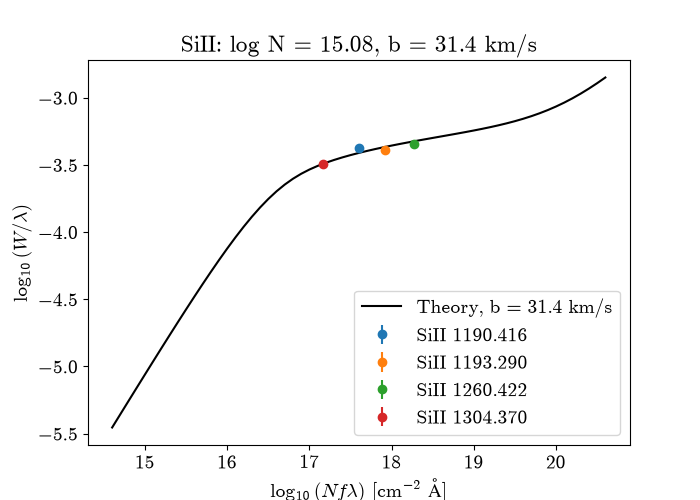

In [15]:
from spectral_diag.plots import plot_curve_of_growth

for species in COG_SPECIES:
    ews = measured_ews(identified, species)
    fig, ax = plot_curve_of_growth(get_lines(species), ews, cog_fits[species])
    plt.show()

| | $\log N$ (cm $^{-2}$) | $b$ (km/s) | $\chi^2$ / dof | Sembach et al. (2001): $\log N$, $b$ |
|---|---|---|---|---|
| S II | 15.33 ± 0.04 | 21.8 ± 2.1 | 5.0 / 1 | 15.46 ± 0.06, 20.1 ± 2.5 |
| Si II | 15.08 ± 0.06 | 31.4 ± 1.0 | 31.4 / 2 | 15.10 ± 0.10, 32.2 ± 2.5 |

The published values (Sembach et al. 2001, arXiv:astro-ph/0108047, Table 5: single-component curves of growth on HST/GHRS and FUSE equivalent widths) are close to ours: Si II and both $b$ agree within the errors, S II is 0.13 dex lower here (2σ).

- **S II is not on the linear part**: its lines sit at the knee of the curve, mildly saturated, so $N$ depends on $b$ too. It is still the best constrained species.
- **Si II is fully saturated**: its four lines sit on the flat part, where $W$ hardly changes with $N$. The ±0.06 dex is the curvature of $\chi^2$ at its minimum and underestimates the real uncertainty. With $\chi^2 = 31$ for 2 degrees of freedom the single-cloud model does not fit well either: the gas has two groups of clouds, at about $-15$ and $+23$ km/s (Sembach et al. 2001), and Si II 1260 is blended with the weak Fe II 1260.5.
- The S II EWs may also be slightly low because the windows of `find_features` stop where the significance drops, which can miss the faint wings of the lines.

### 5.1 Uncertainties: the $\chi^2$ map

The errors above come from the curvature of $\chi^2$ at its minimum: they assume $\chi^2$ is a parabola in $(\log N, b)$. `chi2_map` (`spectral_diag/uncertainty.py`, validated in `08_chi2_map.ipynb`) computes $\chi^2$ on a grid instead: $\log N$ within ±3 dex of the fit (241 points), $b$ from 1 to 100 km/s (150 points, log-spaced).

- The **joint regions** of $(\log N, b)$ are the contours $\Delta\chi^2 = 2.30$, 6.17 and 11.8 (68, 95 and 99.7 %).
- The **interval of one parameter** is where its *profile* (the lowest $\Delta\chi^2$ over the other parameter) stays below 1 (68 %) or 3.84 (95 %).
- Both fits are poor ($\chi^2_\mathrm{min}/\mathrm{dof}$ = 5.0 for S II, 15.7 for Si II): the single-cloud model is too simple, or the EW errors too small. $\chi^2$ is divided by $\chi^2_\mathrm{min}/\mathrm{dof}$ before the levels are applied, which widens the errors by its square root. The raw intervals are printed too.

In [16]:
from dataclasses import replace

from spectral_diag.plots import plot_chi2_map, plot_profiles
from spectral_diag.uncertainty import ONE_PARAMETER_95, chi2_map, profile_interval


def interval_text(interval):
    # "[low, high]", with ">" or "<" where the interval reaches the grid edge
    low = f"{interval.low:.2f}"
    high = f"{interval.high:.2f}"
    if interval.low_at_grid_edge:
        low = "<" + low
    if interval.high_at_grid_edge:
        high = ">" + high
    return f"[{low}, {high}]"


chi2_maps = {}
for species in COG_SPECIES:
    ews = measured_ews(identified, species)
    chi2_maps[species] = chi2_map(get_lines(species), ews, cog_fits[species])

for species, result in chi2_maps.items():
    print(f"{species}: scale {result.scale:.1f}")
    for name, map_used in (("raw", replace(result, scale=1.0)), ("rescaled", result)):
        for parameter in ("logN", "b"):
            interval = profile_interval(map_used, parameter)
            wide = profile_interval(map_used, parameter, ONE_PARAMETER_95)
            print(
                f"  {name:9s} {parameter:4s} 68 % {interval_text(interval):16s} "
                f"95 % {interval_text(wide)}"
            )

SII: scale 5.0
  raw       logN 68 % [15.29, 15.37]   95 % [15.25, 15.41]
  raw       b    68 % [20.00, 23.92]   95 % [18.56, 26.55]
  rescaled  logN 68 % [15.24, 15.43]   95 % [15.16, 15.55]
  rescaled  b    68 % [18.16, 27.46]   95 % [15.53, 38.00]
SiII: scale 15.7
  raw       logN 68 % [15.03, 15.15]   95 % [14.99, 15.22]
  raw       b    68 % [30.44, 32.21]   95 % [29.31, 33.17]
  rescaled  logN 68 % [14.91, 15.45]   95 % [14.81, 16.49]
  rescaled  b    68 % [26.63, 34.98]   95 % [18.32, 38.07]


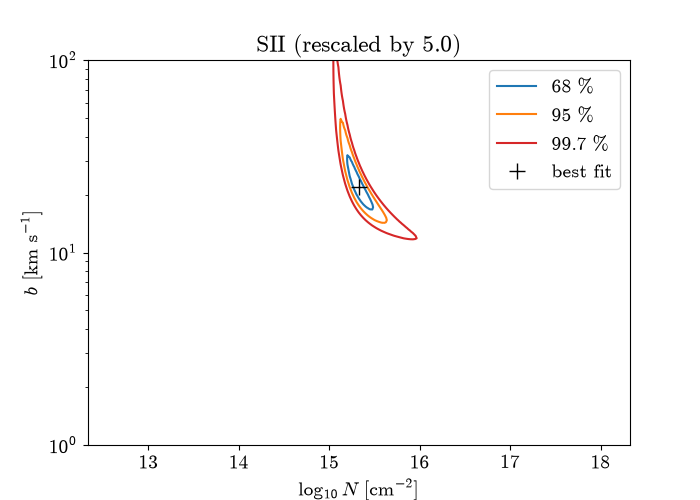

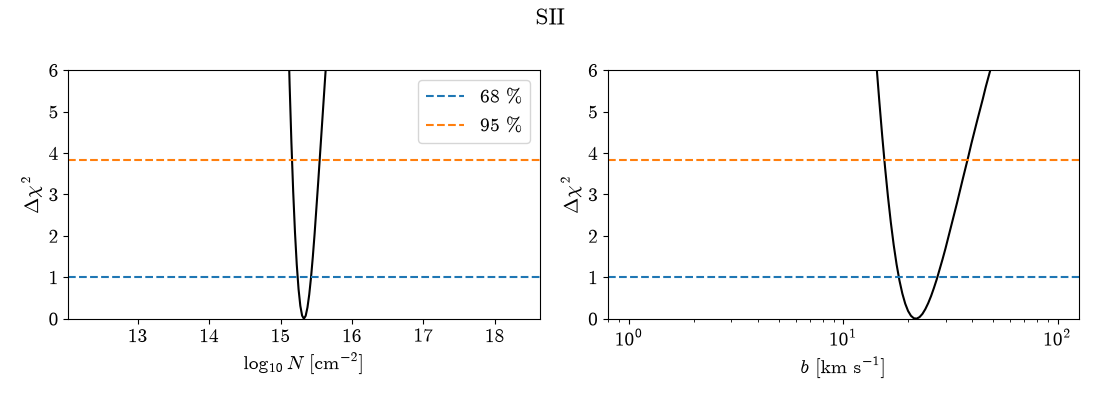

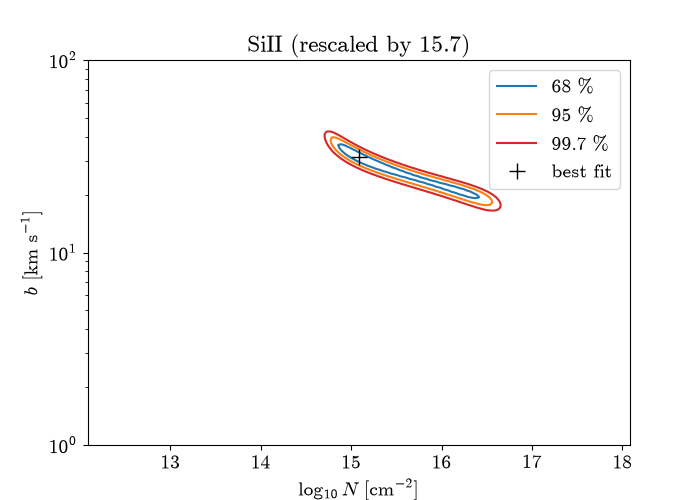

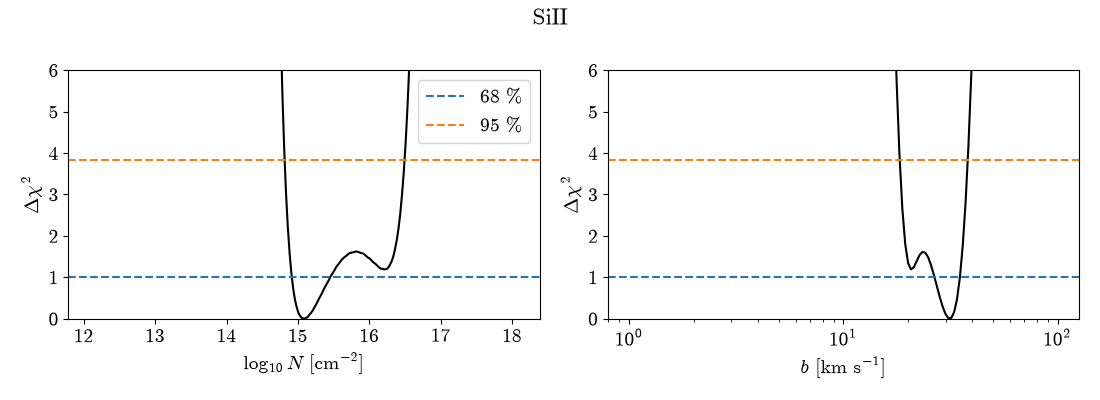

In [17]:
for species, result in chi2_maps.items():
    fig, ax = plot_chi2_map(result, f"{species} (rescaled by {result.scale:.1f})")
    plt.show()
    fig, axes = plot_profiles(result, species)
    plt.show()

| | fit (curvature) | map, rescaled, 68 % | map, rescaled, 95 % | scale |
|---|---|---|---|---|
| S II $\log N$ | 15.33 ± 0.04 | [15.24, 15.43] | [15.16, 15.55] | 5.0 |
| S II $b$ (km/s) | 21.8 ± 2.1 | [18.2, 27.5] | [15.5, 38.0] | |
| Si II $\log N$ | 15.08 ± 0.06 | [14.91, 15.45] | [14.81, 16.49] | 15.7 |
| Si II $b$ (km/s) | 31.4 ± 1.0 | [26.6, 35.0] | [18.3, 38.1] | |

- **Without rescaling**, the map gives the same intervals as the curvature (S II $\log N$ [15.29, 15.37], Si II [15.03, 15.15]): at its very bottom, $\chi^2$ is close to a parabola. The difference comes from the rescaling and from the shape further out.
- **S II**: the joint region is a compact ellipse, a bit longer towards high $b$ (the lines get closer to the linear part there, where $b$ no longer matters). With the rescaling, $\log N = 15.33^{+0.10}_{-0.09}$. The published 15.46 ± 0.06 (Sembach et al. 2001) is just outside our 68 % interval and inside the 95 % one.
- **Si II**: the joint region is a long diagonal valley, and the profile of $\log N$ has **two minima**: the best fit at 15.08 ($b \approx 31$ km/s), and a second one near $\log N \approx 16.2$, $b \approx 21$ km/s, only $\Delta\chi^2 \approx 1.2$ higher. The second one is the solution found with three lines (16.14, $b = 20.7$ km/s). The data cannot choose between them: at 95 %, $\log N$(Si II) is anywhere from 14.8 to 16.5. The ±0.06 of the fit described only the bottom of the first minimum.
- **What this means**: S II gives a column density (to ~0.1 dex); the saturated Si II lines only give a range of 1.7 dex. Its agreement with the published 15.10 is partly luck. A weaker Si II line, such as 1808 Å (outside the COS range), would be needed to pin it down.

## 6. Next steps

- Plots for the oral: the spectrum with the identified lines labelled, and the curves of growth above.